# Portfolio Optimization with Modern Portfolio Theory

## Overview
This project uses Markowitz's Modern Portfolio Theory to build data-driven portfolios from historical price data. Instead of guessing an allocation, it runs a Monte Carlo simulation over thousands of random weight combinations and picks the one with the best risk-adjusted return.

This started as a crypto only analysis, but the underlying math doesn't care what kind of asset it's looking at. It was later generalized to work with any ticker available on Yahoo Finance, so the same code can price a crypto portfolio, a basket of B3 stocks, or a mix of both.

### What it does
* Simulates 100,000 random portfolios to map the risk-return trade-off
* Finds the efficient frontier: the best possible return for each level of risk
* Caps any single asset at 40% of the portfolio to force diversification


## Setup

Four libraries do the work:
* `yfinance` downloads historical price data
* `numpy` handles the matrix math behind the simulations
* `pandas` manages the price and returns tables
* `matplotlib` plots the efficient frontier


In [ ]:
# To fetch historical price data from Yahoo Finance
%pip install yfinance 

# To handle the data tables (DataFrames)
%pip install pandas 

# To perform the heavy math and matrix multiplications
%pip install numpy 

# To create the actual Markowitz graph
%pip install matplotlib


In [2]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Fixed seed so the random portfolios, and every result below, are the same on each run
np.random.seed(42)

## Data Acquisition

First step: pull historical prices for the tickers we care about. We only need the Close price for the calculations that follow.

Tickers can be anything Yahoo Finance recognizes: crypto (`BTC-USD`), US stocks (`AAPL`), or B3 stocks (`PETR4.SA`, `VALE3.SA`, `ITUB4.SA`).


In [3]:
tickers = ['PETR4.SA', 'VALE3.SA', 'ITUB4.SA', 'WEGE3.SA']
start_date = '2020-01-01'
end_date = '2025-12-31'
# Yahoo returns the columns in alphabetical order, so put them back in the same order as tickers
data = yf.download(tickers, start=start_date, end=end_date)['Close'][tickers]
data.head()


[                       0%                       ]

[**********************50%                       ]  2 of 4 completed

[**********************50%                       ]  2 of 4 completed

[*********************100%***********************]  4 of 4 completed

Ticker,PETR4.SA,VALE3.SA,ITUB4.SA,WEGE3.SA
Date,,,,
2020-01-02,8.289425,29.317493,22.936806,15.458444
2020-01-03,8.221921,29.101641,22.695557,15.261047
2020-01-06,8.319123,28.928970,22.357811,15.300528
2020-01-07,8.286724,29.139421,21.839125,15.418966
2020-01-08,8.235421,29.144815,21.483278,14.835545


## Handling Missing Data

Stocks don't always have a price on every date. A company that went public after the start date has no history before its IPO, and a stock can be suspended for a few days. Left unfiltered, these gaps distort the mean returns and, more noticeably, the covariance matrix.

We handle this in two steps:
1. **Drop tickers with too much missing data.** If a stock is missing more than 10% of its prices (for example, it listed later than the others), it's excluded instead of shrinking the dataset for every other stock.
2. **Keep only the days when every stock traded.** This also makes it safe to mix stocks from exchanges with different holidays, like B3 and the NYSE. Filling the gaps with the previous price instead would create fake days with a 0% return, which makes a stock look less volatile and less correlated with the others than it really is.

In [4]:
# Check how much data is missing per ticker
missing_pct = data.isna().mean()
print("Missing data by ticker:\n", missing_pct, "\n")

# Drop tickers with excessive missing data instead of letting them shrink the whole dataset
tickers_to_drop = missing_pct[missing_pct > 0.10].index.tolist()
if tickers_to_drop:
    print(f"Dropping tickers with more than 10% missing data: {tickers_to_drop}")
    data = data.drop(columns=tickers_to_drop)
    tickers = [t for t in tickers if t not in tickers_to_drop]

# Keep only the days when every remaining stock traded, so all returns cover the same dates
data = data.dropna()

print(f"Final dataset: {data.shape[0]} trading days across {data.shape[1]} tickers")
data.head()


Missing data by ticker:
 Ticker
PETR4.SA    0.0
VALE3.SA    0.0
ITUB4.SA    0.0
WEGE3.SA    0.0
dtype: float64 

Final dataset: 1494 trading days across 4 tickers


Ticker,PETR4.SA,VALE3.SA,ITUB4.SA,WEGE3.SA
Date,,,,
2020-01-02,8.289425,29.317493,22.936806,15.458444
2020-01-03,8.221921,29.101641,22.695557,15.261047
2020-01-06,8.319123,28.928970,22.357811,15.300528
2020-01-07,8.286724,29.139421,21.839125,15.418966
2020-01-08,8.235421,29.144815,21.483278,14.835545


## Daily Returns

Prices on their own don't compare well across stocks (a R$ 40 stock and a R$ 300 stock aren't on the same scale), so we work with daily percentage returns instead.

**Formula:** $\text{Return} = \frac{\text{Price}_{\text{today}} - \text{Price}_{\text{yesterday}}}{\text{Price}_{\text{yesterday}}}$

We use simple returns rather than log returns on purpose. A portfolio's daily return is exactly the weighted average of its stocks' simple returns, which is what every formula below relies on. Log returns add up nicely over time, but not across assets: averaging them understates what a portfolio actually earns, and penalizes diversified portfolios the most.

The first row has no prior day to compare against, so it comes out as `NaN`. `dropna()` removes it.

In [5]:
# Simple daily returns: (Price_today / Price_yesterday) - 1
returns = data.pct_change().dropna()

print(returns.head())

Ticker      PETR4.SA  VALE3.SA  ITUB4.SA  WEGE3.SA
Date                                              
2020-01-03 -0.008143 -0.007363 -0.010518 -0.012769
2020-01-06  0.011822 -0.005933 -0.014882  0.002587
2020-01-07 -0.003895  0.007275 -0.023199  0.007741
2020-01-08 -0.006191  0.000185 -0.016294 -0.037838
2020-01-09 -0.003279 -0.013146 -0.019933 -0.014784


## Mean Returns and Covariance

Two numbers drive the model:

**Mean returns**: the average daily return per asset, annualized by multiplying by 252 trading days. This is the expected reward.

**Covariance matrix**: how each pair of assets moves relative to the others. Assets that move together add less diversification benefit than assets that move independently or inversely.

Portfolio risk isn't just the average risk of its parts, it depends heavily on these correlations. Combining assets that don't move in lockstep can lower total risk without giving up return.


In [6]:
# Average daily return for each token
mean_returns = returns.mean()
print("Mean Returns:\n", mean_returns, "\n")

# Covariance matrix (The risk relationship between tokens)
cov_matrix = returns.cov()
print("Covariance Matrix:\n", cov_matrix, "\n")

# Annual risk-free rate for the Sharpe ratio: the average CDI between two dates, from the
# Banco Central do Brasil API (series 4389, CDI annualized on a 252 business day basis)
def average_cdi(start, end):
    url = (
        "https://api.bcb.gov.br/dados/serie/bcdata.sgs.4389/dados?formato=json"
        f"&dataInicial={start:%d/%m/%Y}&dataFinal={end:%d/%m/%Y}"
    )
    return pd.read_json(url)['valor'].mean() / 100

risk_free_rate = average_cdi(returns.index[0], returns.index[-1])
print(f"Average CDI from {returns.index[0].date()} to {returns.index[-1].date()}: {risk_free_rate:.2%} per year")


Mean Returns:
 Ticker
PETR4.SA    0.001195
VALE3.SA    0.000830
ITUB4.SA    0.000530
WEGE3.SA    0.001033
dtype: float64 

Covariance Matrix:
 Ticker    PETR4.SA  VALE3.SA  ITUB4.SA  WEGE3.SA
Ticker                                          
PETR4.SA  0.000691  0.000267  0.000247  0.000187
VALE3.SA  0.000267  0.000498  0.000153  0.000128
ITUB4.SA  0.000247  0.000153  0.000368  0.000123
WEGE3.SA  0.000187  0.000128  0.000123  0.000540 



Average CDI from 2020-01-03 to 2025-12-30: 9.68% per year


## Portfolio Return, Risk, and Sharpe Ratio

**Portfolio return** is the weighted average of each asset's return:
$$R_p = \sum_{i=1}^{n} w_i \mu_i$$
`np.dot(weights, mean_returns) * 252`

**Portfolio risk** accounts for how assets move together, not just their individual volatility:
$$\sigma_p = \sqrt{w^T \Sigma w}$$
`np.sqrt(np.dot(weights.T, np.dot(cov_matrix * 252, weights)))`

**Sharpe ratio** measures return per unit of risk:
$$Sharpe = \frac{R_p - R_f}{\sigma_p}$$

$R_f$ is the annual risk-free rate, what you'd earn with no risk at all. Assuming it's 0 inflates every portfolio's Sharpe ratio, so we use a real one.

The example portfolio is made of B3 stocks, which trade in reais, so the benchmark is the **CDI**: the Brazilian interbank rate that almost every fixed income investment in Brazil tracks. We use its average over the same period as the price data, pulled from the Banco Central do Brasil API. For US stocks or crypto priced in dollars, a US Treasury bill rate would be the right benchmark instead.


In [7]:
# Step A: Create random weights that sum to 1
weights = np.random.random(len(tickers))
weights /= np.sum(weights)

# Step B: Calculate Annualized Return
# (Daily Return * 252 trading days)
p_ret = np.dot(weights, mean_returns) * 252

# Step C: Calculate Annualized Volatility (Risk)
# Formula: sqrt(Weights * Covariance * Weights) * sqrt(252)
p_vol = np.sqrt(np.dot(weights.T, np.dot(cov_matrix * 252, weights)))

print(f"Random Weights: {weights}")
print(f"Expected Annual Return: {p_ret:.2%}")
print(f"Expected Annual Risk: {p_vol:.2%}")


Random Weights: [0.14102156 0.35796222 0.27560979 0.22540643]
Expected Annual Return: 21.28%
Expected Annual Risk: 25.45%


## Monte Carlo Simulation

There's no closed-form way to pick the best weights across multiple assets, so we brute-force it: generate 100,000 random weight combinations, calculate return and risk for each, and see where they land. Plotting all of them traces out the efficient frontier.


## Concentration Limit

Left unconstrained, the simulation tends to favor a single asset with the best historical return, which isn't a real diversification strategy. We cap each asset at 40% of the portfolio: any random weight set that exceeds this gets discarded and re-rolled until it passes.


In [8]:
# 1. Initialization
num_portfolios = 100000  # Note: 100k portfolios will take a few seconds
num_assets = len(tickers)

all_weights = np.zeros((num_portfolios, num_assets))
ret_arr = np.zeros(num_portfolios)
vol_arr = np.zeros(num_portfolios)
sharpe_arr = np.zeros(num_portfolios)

# 2. The Simulation Loop
for i in range(num_portfolios):
    
    # Step A: Generate Random Weights that sum to 1 with 40% Concentration Limit
    valid_portfolio = False
    while not valid_portfolio:
        weights = np.random.random(num_assets)
        weights /= np.sum(weights)
        
        # Applying the 40% Concentration Limit
        if np.max(weights) <= 0.40:
            valid_portfolio = True

    all_weights[i,:] = weights
    
    # Step B: Calculate Annualized Return (R_p)
    portfolio_return = np.dot(weights, mean_returns) * 252
    ret_arr[i] = portfolio_return
    
    # Step C: Calculate Annualized Volatility (sigma_p)
    portfolio_volatility = np.sqrt(np.dot(weights.T, np.dot(cov_matrix * 252, weights)))
    vol_arr[i] = portfolio_volatility
    
    # Step D: Calculate Sharpe Ratio
    sharpe_arr[i] = (ret_arr[i] - risk_free_rate) / vol_arr[i]

# 3. Frontier calculation
# Sorting results to find the "edge" of the cloud
idx = np.argsort(vol_arr)
vol_sorted = vol_arr[idx]
ret_sorted = ret_arr[idx]

frontier_vol = []
frontier_ret = []

max_ret = -np.inf
for v, r in zip(vol_sorted, ret_sorted):
    if r > max_ret:
        frontier_vol.append(v)
        frontier_ret.append(r)
        max_ret = r

print("Monte Carlo Simulation with 40% constraint complete.")


Monte Carlo Simulation with 40% constraint complete.


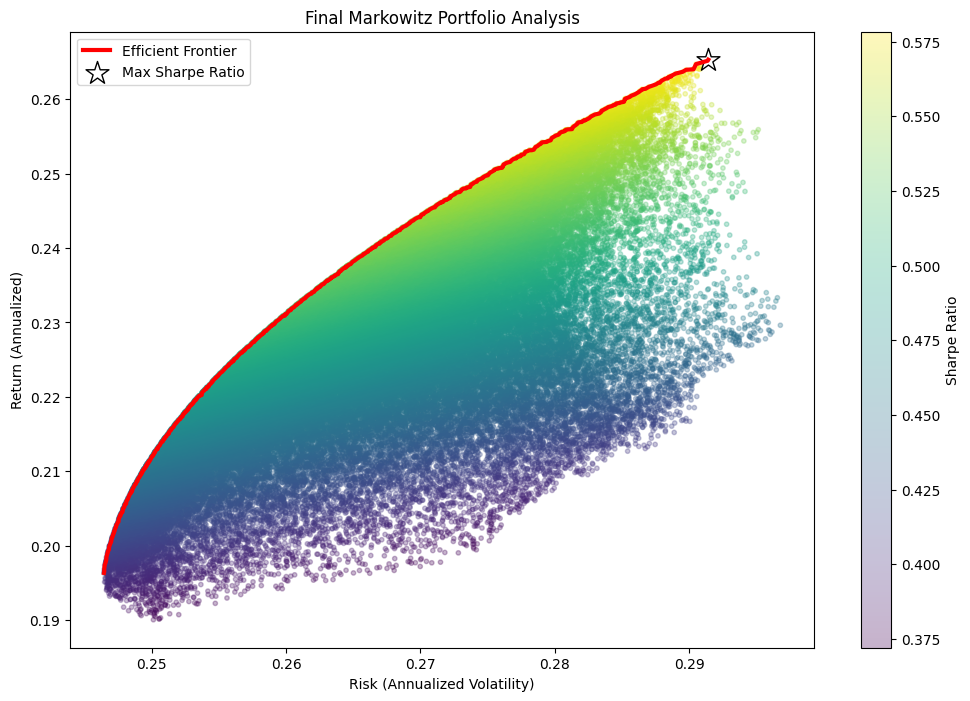

PETR4.SA: 39.41%
VALE3.SA: 21.00%
ITUB4.SA: 0.28%
WEGE3.SA: 39.31%


In [9]:
plt.figure(figsize=(12, 8))

# 1. The Cloud (All portfolios)
plt.scatter(vol_arr, ret_arr, c=sharpe_arr, cmap='viridis', alpha=0.3, s=10)
plt.colorbar(label='Sharpe Ratio')

# 2. The Frontier Line (The logic you just wrote!)
plt.plot(frontier_vol, frontier_ret, color='red', linewidth=3, label='Efficient Frontier')

# 3. The Optimal Point
max_sharpe_idx = sharpe_arr.argmax()
plt.scatter(vol_arr[max_sharpe_idx], ret_arr[max_sharpe_idx], color='white', marker='*', s=300, edgecolors='black', label='Max Sharpe Ratio')

plt.title('Final Markowitz Portfolio Analysis')
plt.xlabel('Risk (Annualized Volatility)')
plt.ylabel('Return (Annualized)')
plt.legend()
plt.show()

# Display the optimal weights
optimal_weights = all_weights[max_sharpe_idx]
for i, ticker in enumerate(tickers):
    print(f"{ticker}: {optimal_weights[i]:.2%}")

## Out-of-Sample Backtest

Everything above has a problem: the simulation picks the weights that performed best on a dataset, and then we judge how good those weights are using that same dataset. That's not a fair test, it's the simulation grading its own homework, and it overstates how good the portfolio really is.

A fairer test is to split the history in two: use the first part (train) to run the simulation and pick the max Sharpe portfolio, then check how that exact portfolio would have performed on the second part (test), data it never saw when the weights were chosen.

Each period is measured against its own average CDI. Using the rate of the whole period would let the training step peek at future interest rates, and in this sample the CDI went from about 9% in the training years to about 14% in the test period.

In [10]:
# Split the return series: train to search for weights, test to evaluate them
split_idx = int(len(returns) * 0.8)
train_returns = returns.iloc[:split_idx]
test_returns = returns.iloc[split_idx:]

# Each period uses its own CDI, so the weights are chosen without knowing future interest rates
train_rf = average_cdi(train_returns.index[0], train_returns.index[-1])
test_rf = average_cdi(test_returns.index[0], test_returns.index[-1])

train_mean = train_returns.mean()
train_cov = train_returns.cov()

# Re-run the same simulation, but only on the training window
num_portfolios_backtest = 20000
backtest_weights = np.zeros((num_portfolios_backtest, num_assets))
backtest_sharpe = np.zeros(num_portfolios_backtest)

for i in range(num_portfolios_backtest):
    valid_portfolio = False
    while not valid_portfolio:
        w = np.random.random(num_assets)
        w /= np.sum(w)
        if np.max(w) <= 0.40:
            valid_portfolio = True

    backtest_weights[i, :] = w
    ret = np.dot(w, train_mean) * 252
    vol = np.sqrt(np.dot(w.T, np.dot(train_cov * 252, w)))
    backtest_sharpe[i] = (ret - train_rf) / vol

best_train_idx = backtest_sharpe.argmax()
backtest_optimal_weights = backtest_weights[best_train_idx]

train_ret = np.dot(backtest_optimal_weights, train_mean) * 252
train_vol = np.sqrt(np.dot(backtest_optimal_weights.T, np.dot(train_cov * 252, backtest_optimal_weights)))
train_sharpe = backtest_sharpe[best_train_idx]

# Apply those same weights (chosen using only training data) to the unseen test period
test_mean = test_returns.mean()
test_cov = test_returns.cov()
test_ret = np.dot(backtest_optimal_weights, test_mean) * 252
test_vol = np.sqrt(np.dot(backtest_optimal_weights.T, np.dot(test_cov * 252, backtest_optimal_weights)))
test_sharpe = (test_ret - test_rf) / test_vol

print(f"Weights chosen using only training data ({train_returns.index[0].date()} to {train_returns.index[-1].date()}):")
for i, ticker in enumerate(tickers):
    print(f"  {ticker}: {backtest_optimal_weights[i]:.2%}")

print(f"\nIn-sample (training) performance, against a CDI of {train_rf:.2%}:")
print(f"  Return: {train_ret:.2%}  Risk: {train_vol:.2%}  Sharpe: {train_sharpe:.2f}")

print(f"\nOut-of-sample performance on unseen data ({test_returns.index[0].date()} to {test_returns.index[-1].date()}), against a CDI of {test_rf:.2%}:")
print(f"  Return: {test_ret:.2%}  Risk: {test_vol:.2%}  Sharpe: {test_sharpe:.2f}")


Weights chosen using only training data (2020-01-03 to 2024-10-16):
  PETR4.SA: 39.83%
  VALE3.SA: 18.65%
  ITUB4.SA: 1.92%
  WEGE3.SA: 39.60%

In-sample (training) performance, against a CDI of 8.64%:
  Return: 31.97%  Risk: 31.35%  Sharpe: 0.74

Out-of-sample performance on unseen data (2024-10-17 to 2025-12-30), against a CDI of 13.81%:
  Return: 4.45%  Risk: 17.41%  Sharpe: -0.54
